# ДДЗ-2. Универсальная наклейка против детектора YOLOv8

## Описание лабораторной работы
В отличие от ДДЗ-1, где атаковался компактный классификатор цифр, в этой работе объектом исследования выступает полноценная сверточная нейросеть для компьютерного зрения — **детектор объектов YOLOv8n** (архитектура Nano, объем весов ~6 МБ). Модель предобучена на датасете Microsoft COCO и способна локализовать и распознавать 80 классов объектов (люди, автомобили, электроника и др.), возвращая координаты ограничивающих рамок (bounding boxes) и вероятности классов.

Цель работы — симулировать сценарий обхода систем видеонаблюдения. Вам предстоит разработать **универсальную цифровую наклейку (adversarial patch)** — локализованный узор фиксированного размера, который при наложении на изображение радикально искажает логику работы детектора в области атаки.

Сеть заморожена, её дообучение не требуется. Работа включает в себя три вычислительных эксперимента: два метода оптимизации первого порядка (**White-Box**) и один метод нулевого порядка (**Black-Box**).

---

## План выполнения (Структура ноутбука)

### Подготовительный этап
*   **Разделы 0–1 (Автоматически):** Загрузка предобученных весов YOLOv8n и выборки из 128 тестовых изображений датасета COCO. Разбор внутренней логики детектора: извлечение кандидатов на bounding boxes и анализ сырых логитов (raw logits) до применения операции Non-Maximum Suppression (NMS).

### Экспериментальная часть
*   **Шаг 1. Белый ящик: Генерация фейкового объекта (Раздел 2)**
    *   **Условия:** Полный доступ к архитектуре, весам сети и градиентам.
    *   **Задача:** С помощью итеративного метода PGD вычислить текстуру патча, которая при наложении поверх реальных объектов заставит YOLOv8n стабильно распознавать в этой зоне ложный класс **«cell phone» (мобильный телефон)**. Градиенты функции потерь пробрасываются напрямую в пиксели наклейки.
*   **Шаг 2 (★). Белый ящик: Режим «Невидимки» (Раздел 3)**
    *   **Условия:** Полный доступ к градиентам модели.
    *   **Задача:** Модифицировать целевую функцию оптимизации патча так, чтобы решить обратную задачу — полностью скрыть присутствие человека (класс **«person»**) из поля зрения детектора в области наложения узора.
*   **Шаг 3 (★★). Чёрный ящик: Оптимизация нулевого порядка (Раздел 4)**
    *   **Условия:** Веса и градиенты сети недоступны. Модель скрыта за API, которое на вход принимает изображение, а на выход возвращает единственное число — confidence score для конкретной зоны.
    *   **Задача:** Текстура узора параметризуется вектором всего из 6 чисел. Оптимизация выполняется безградиентным методом (комбинация случайного поиска / Random Search и алгоритма восхождения к вершине / Hill Climbing) на основе анализа возвращаемых моделью скоров.

---

## Технические особенности и регламент

*   **Вычислительная сложность:** Полный прогон ноутбука занимает около **4 минут на CPU**. Основная часть времени тратится на 60 итераций градиентного обучения универсального патча на Шаге 1.
*   **Требования к оформлению:** 
    *   Заполняйте только программный код внутри блоков с пометкой `✍️ ДЕЛАЙТЕ`.
    *   Корректность выполнения проверяется автоматическими юнит-тестами в ячейках `✅ Самопроверка`.
    *   **Запрещено** переименовывать, удалять или изменять типы ключевых переменных: `net`, `patch`, `wb_pmax`, `fake_ok`, `sup_dropped`, `bb_delta_train`, `bb_delta_held`, `bb_queries`.

---

## 0. Данные и инициализация детектора



In [1]:
# Детектор и данные. Скачивается один раз и кешируется во временной папке.
import sys, time, warnings, zipfile, urllib.request
from pathlib import Path
import tempfile

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings('ignore')
sys.stdout.reconfigure(encoding='utf-8', errors='replace')

TMP = Path(tempfile.gettempdir()) / 'opencode'
TMP.mkdir(exist_ok=True)

from ultralytics import YOLO

# ---- веса YOLOv8n (6.2 МБ) ----
WTS = TMP / 'yolov8n.pt'
if not WTS.exists():
    url = ('https://github.com/ultralytics/assets/releases/'
           'download/v8.4.0/yolov8n.pt')
    print('скачиваю yolov8n.pt (~6 МБ)...')
    for attempt in range(5):
        try:
            urllib.request.urlretrieve(url, WTS)
            break
        except Exception as e:
            print(f'  попытка {attempt+1} не удалась: {type(e).__name__}')
            time.sleep(5)

model = YOLO(str(WTS))
net = model.model.eval()          # ← сюда пойдёт градиент (белый ящик)
names = model.names
print('детектор:', net.__class__.__name__,
      f'| {sum(p.numel() for p in net.parameters())/1e6:.1f} M весов |',
      'CPU-режим')

# ---- данные coco128: 128 фото + настоящие метки YOLO-формата ----
ROOT = TMP / 'yolo_probe' / 'coco128'
if not list((ROOT / 'images' / 'train2017').glob('*.jpg')):
    url = ('https://github.com/ultralytics/assets/releases/'
           'download/v0.0.0/coco128.zip')
    zpath = TMP / 'yolo_probe' / 'coco128.zip'
    zpath.parent.mkdir(exist_ok=True)
    if not zpath.exists():
        print('скачиваю coco128 (~7 МБ)...')
        for attempt in range(5):
            try:
                urllib.request.urlretrieve(url, zpath)
                break
            except Exception:
                time.sleep(5)
    with zipfile.ZipFile(zpath) as zf:
        zf.extractall(zpath.parent)
print('фото:', len(list((ROOT / 'images' / 'train2017').glob('*.jpg'))))

детектор: DetectionModel | 3.2 M весов | CPU-режим
фото: 128


## 0. Как наклейка попадает на фото (и подготовка фотографий)

Предобработка фотографий устроена просто:
* Каждая картинка сжимается до рабочего разрешения **320×320**.
* Значения цвета делятся на **255**, чтобы они лежали в диапазоне `[0, 1]`.

### Как устроен патч?
Узор (патч) — это обычный тензор вида `(3, H, W)`, где 3 — это каналы цвета. «Пришить» его к фотографии — значит записать его значения в квадратный кусок тензора исходного фото. Прямоугольник наклейки просто затирает часть пикселей.

### Почему это работает?
> **Ключевой факт, на котором держится всё задание:** присваивание в срез дифференцируемо.

Когда ниже мы будем обновлять патч градиентными шагами, автоград **PyTorch** пройдёт от функции потерь назад через всю сеть и через запись в срез — и вернёт градиент по каждому пикселю самого патча. Поэтому патч обучается точно так же, как веса нейросети или пиксели картинки в ДДЗ-1.

### Подготовка выборки
В коде ниже делается выборка: **8 фотографий** с крупным человеком (метка `person` считывается из YOLO-разметки). Патч будет пришиваться ровно в центр силуэта этого человека.


8 фото-жертв: ['000000000036', '000000000077', '000000000086', '000000000110', '000000000113', '000000000136', '000000000165', '000000000192']
места патча (центры): [(214, 197), (46, 213), (135, 185), (212, 158), (61, 129), (17, 208), (220, 192), (207, 242)]


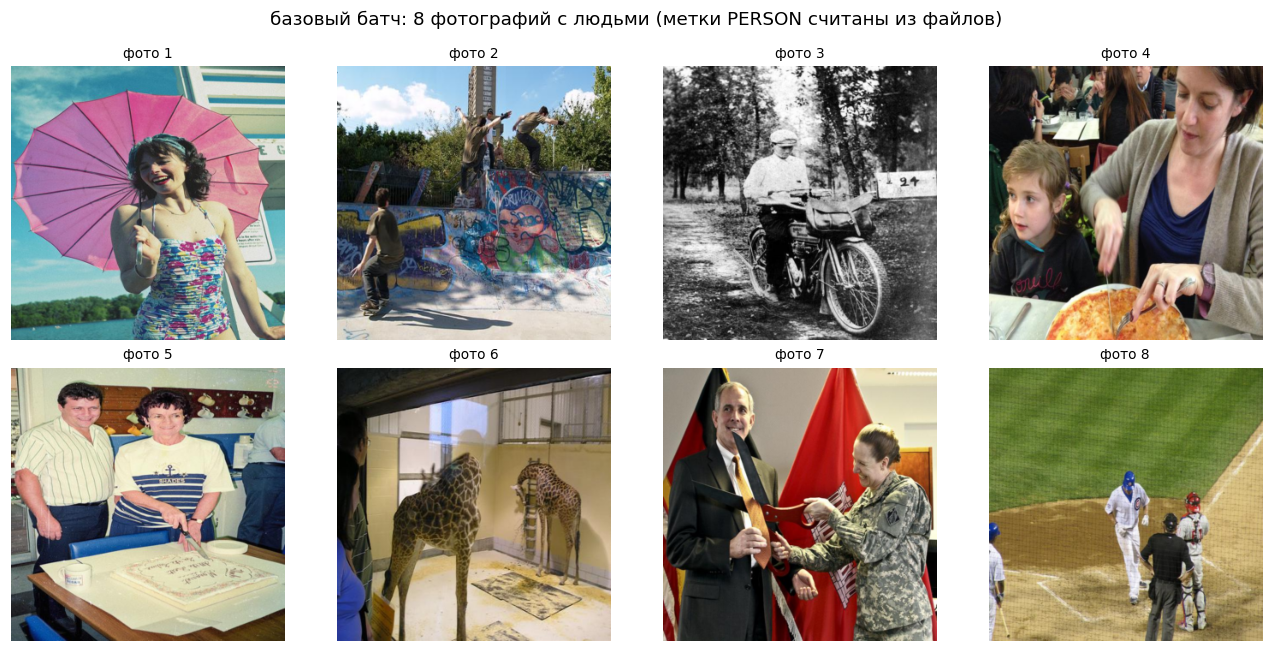

In [1]:
SZ, TGT = 320, 67            # рабочее разрешение и целевой класс (cell phone)
assert names[TGT] == 'cell phone'


def load(path, sz=SZ):
    im = Image.open(path).convert('RGB').resize((sz, sz), Image.BILINEAR)
    a = np.asarray(im).astype(np.float32) / 255.0
    return torch.from_numpy(a).permute(2, 0, 1)


def stamp(x, patch, places, ps):
    """пришиваем патч к каждой картинке батча; возвращает НОВЫЙ тензор"""
    x = x.clone()
    for i, (cx, cy) in enumerate(places):
        x0 = min(max(cx - ps // 2, 0), SZ - ps)
        y0 = min(max(cy - ps // 2, 0), SZ - ps)
        x[i, :, y0:y0 + ps, x0:x0 + ps] = patch
    return x


def detect(x, conf=0.05):
    """настоящий детектор (post-NMS): список результатов по фото"""
    npim = (x.detach().permute(0, 2, 3, 1).numpy() * 255).astype(np.uint8)
    return model.predict(source=list(npim), verbose=False, imgsz=SZ,
                         conf=conf, iou=0.45)


def best_conf(x, cls):
    """для каждого фото — максимальная conf-уверенность класса cls (0, если нет)"""
    out = []
    for r in detect(x):
        cc = [float(c) for c, k in zip(r.boxes.conf, r.boxes.cls)
              if int(k) == cls]
        out.append(max(cc) if cc else 0.0)
    return out


# ---- 8 фото с крупным человеком (класс 0): на них «рисуем» патч ----
files = {p.stem for p in (ROOT / 'images' / 'train2017').glob('*.jpg')}
persons = []
for lp in sorted((ROOT / 'labels' / 'train2017').glob('*.txt')):
    if lp.stem not in files:
        continue
    for line in lp.read_text(encoding='utf-8',
                             errors='replace').splitlines():
        w = line.split()
        if w and int(w[0]) == 0:                  # метка person
            xc, yc, bh = float(w[1]), float(w[2]), float(w[4])
            if bh > 0.4:                          # крупный человек
                persons.append((lp.stem, int(yc * SZ), int(xc * SZ)))
                break                             # по одному человеку на фото
persons = persons[:8]
imgs = torch.stack([load(ROOT / 'images' / 'train2017' / f'{st}.jpg')
                    for st, *_ in persons])
places = [(cx, cy) for _, cy, cx in persons]
print('8 фото-жертв:', [st for st, *_ in persons])
print('места патча (центры):', places)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j in range(4):
    axes[0, j].imshow(imgs[j].permute(1, 2, 0).numpy())
    axes[0, j].set_title(f'фото {j+1}', fontsize=9)
    axes[0, j].axis('off')
    axes[1, j].imshow(imgs[4 + j].permute(1, 2, 0).numpy())
    axes[1, j].set_title(f'фото {j+5}', fontsize=9)
    axes[1, j].axis('off')
plt.suptitle('базовый батч: 8 фотографий с людьми (метки PERSON считаны из файлов)')
plt.tight_layout(); plt.show()

## 1. Подсматриваем внутрь сети: анкоры и сырые логиты

В отличие от классификатора из ДДЗ-1, который выдавал всего 10 оценок классов на картинку, детектор устроен иначе. 

### Как работают анкоры?
Детектор раскладывает по всему кадру **2100 рамок-кандидатов** (они называются **анкорами**) и для каждой из них оценивает все 80 классов датасета COCO. Вся эта таблица возвращается в виде тензора:

```python
ret = net(x)                 # ret[1] — служебный dict внутри детектора
scores = ret[1]['scores']    # (B, 80, 2100): фото × класс × анкор
```

> 🎯 **Цель атаки:** Для нашей задачи важен срез `scores[:, 67, :]`. Класс `67` — это **«cell phone»** (мобильный телефон). Мы получаем 2100 логитов этого класса для каждого фото и в ходе атаки будем целенаправленно поднимать их вверх.

---

### Почему мы используем сырые логиты?
Мы работаем напрямую с **сырыми логитами**, а не с вероятностями (сигмоидами от логитов). Это важный методический прием:

* **Проблема сигмоиды:** Если вероятность класса близка к `0` или `1`, производная сигмоиды становится близкой к нулю. Из-за этого градиент, проходя через нее, затухает.
* **Преимущество логитов:** На сырых логитах градиент всегда остаётся большим, что обеспечивает стабильное обучение патча.

*Примечание: Точно такой же подход использовался в ДДЗ-1, где функция кросс-энтропии также принимала на вход логиты.*


In [1]:
# сырые логиты: что сеть видит ДО атаки
with torch.no_grad():
    ret = net(imgs[:2])
    scores = ret[1]['scores']
print('scores:', tuple(scores.shape), '| логиты в диапазоне',
      f'[{float(scores.min()):.1f} … {float(scores.max()):.1f}]')
z_cp = ret[1]['scores'][:, TGT, :]
print(f'p_max(cell phone) до атаки: {float(z_cp.sigmoid().max()):.2e} '
      '(по сути ноль)')

scores: (2, 80, 2100) | логиты в диапазоне [-49.2 … 2.6]
p_max(cell phone) до атаки: 8.98e-04 (по сути ноль)


## 2. Шаг 1 (основной): белый ящик — фейковый «cell phone»

**Атака типа «Белый ящик» (White Box)** означает, что у атакующего есть полный доступ к системе: известны все веса нейросети и есть возможность честно считать градиенты. 

Метод атаки здесь принципиально такой же, как **PGD в ДДЗ-1**, но с одним ключевым отличием: градиент берётся не по пикселям исходного изображения, а по **3072 числам патча** (его размерность: $3 \times 32 \times 32$).

### 📉 Функция потерь (Loss Function)
Мы не оптимизируем все анкоры подряд. Из всей матрицы логитов класса *«cell phone»* (8 фотографий $\times$ 2100 анкоров) выбираются **32 самых сильных отклика**. Слабые анкоры все равно не смогут обнаружить фейковый класс, поэтому тратить на них ресурс оптимизатора бесполезно. 

Мы максимизируем среднее значение этих топовых логитов:

$$\mathcal{L}(\mathrm{patch}) = -\;\mathrm{mean}\left(\mathrm{top\text{-}32}\; z_{67}\right)$$

---

### ⚙️ Параметры оптимизации
* **Оптимизатор:** Adam
* **Скорость обучения (Learning Rate):** `0.15`
* **Количество итераций:** `60` шагов
* **Проекция (Clamping):** После каждого шага значения патча жестко обрезаются (clipping) до диапазона `[0, 1]`. Наклейка обязана оставаться реалистичным изображением.

> 💡 **Универсальность:** Один и тот же патч пришивается на все 8 фотографий в одно и то же место. Благодаря этому на выходе получается **универсальная наклейка**, а не подделка под какой-то один конкретный кадр.

---

### 📊 Контроль метрик и финальный тест
1. **Мониторинг (`wb_pmax`):** В процессе обучения мы следим за максимумом вероятности класса *«cell phone»* (сигмоида от логита) по всем анкорам и фотографиям. До начала атаки этот показатель практически равен нулю.
2. **«Честный» финальный тест:** После завершения оптимизации обученный патч тестируется через стандартную процедуру детекции `model.predict`. Модель применяет алгоритм подавления немаксимумов (**NMS**) для отфильтровывания дублирующих рамок. Наша цель — чтобы фейковая рамка мобильного телефона успешно выжила после всех этих жестких фильтров.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 1, основной): белый ящик.

torch.manual_seed(1)
patch = torch.rand(3, 32, 32, requires_grad=True)     # начальный узор — шум
opt = torch.optim.Adam(..., lr=0.15)                  # оптимизатор ПО ПАТЧУ
wb_pmax = []                                          # история p_max(cell phone)

for it in range(61):
    if it:
        # 1) ret = net(stamp(imgs, patch, places, 32))
        # 2) z   = ret[1]['scores'][:, TGT, :]           # сырые логиты (B, 2100)
        # 3) loss = -(z.topk(32, dim=1).values).mean()    # PGD-шаг
        # 4) loss.backward(); opt.step()
        # 5) patch.clamp_(0, 1) — патч остаётся «настоящим» изображением
        ...
    if it % 15 == 0:
        # замер: максимум сигмоиды по всем анкорам и фото
        ...
        print(f'шаг {it:2d}: p_max(cell phone) = {wb_pmax[-1]:.4f}')

wb_patch = patch.detach().clone()   # финальный патч (для следующих ячеек)
print('итоговая p_max:', round(wb_pmax[-1], 3))

In [ ]:
# ✅ Самопроверка (Шаг 1): детектор видит «cell phone», которого нет
# ожидает: wb_pmax (история p_max, минимум с 16 элементов)
assert len(wb_pmax) >= 5, 'нужно печатать каждые 15 шагов (it % 15 == 0)'
assert wb_pmax[-1] > 0.8, f'p_max = {wb_pmax[-1]:.3f} — не дожали 60 шагов'
assert wb_pmax[1] > 0.5, f'p_max на шаге 15 = {wb_pmax[1]:.3f}'
print(f'✅ белый ящик: p_max(cell phone) {wb_pmax[0]:.3f} → {wb_pmax[-1]:.3f}')

In [ ]:
# Настоящий детектор (post-NMS) до и после атаки. Красным — cell phone.
def dets_str(r, top=4):
    dd = [(names[int(k)], round(float(v), 2))
          for k, v in zip(r.boxes.cls[:top], r.boxes.conf[:top])]
    return ', '.join(f'{n} {c:.2f}' for n, c in dd)


fig, axes = plt.subplots(2, 3, figsize=(12.5, 8))
fake_ok = 0
for j in range(3):
    axes[0, j].imshow(imgs[j].permute(1, 2, 0).numpy())
    axes[0, j].axis('off')
    axes[0, j].set_title('без патча: ' + dets_str(detect(imgs[j:j + 1])[0]),
                         fontsize=8)

    st = stamp(imgs[j:j + 1], wb_patch, places[j:j + 1], 32)
    r = detect(st)[0]
    axes[1, j].imshow(st[0].permute(1, 2, 0).numpy())
    axes[1, j].axis('off')
    axes[1, j].set_title('с патчем: ' + dets_str(r), fontsize=8)

    for c, v, box in zip(r.boxes.cls, r.boxes.conf, r.boxes.xyxy):
        if names[int(c)] == 'cell phone':
            fake_ok += 1 if float(v) > 0.3 else 0
            x1, y1, x2, y2 = [float(b) for b in box]
            axes[1, j].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                               fill=False, ec='red', lw=2))
plt.suptitle('сквозь детектор: сверху честные фото, снизу — с наклейкой',
             fontsize=11)
plt.tight_layout(); plt.show()
print('фейков (cell phone, conf>0.3) на 3 показанных фото:', fake_ok)

# на будущее — сохраняем патч как настоящую наклейку
from PIL import Image as PILImage
pim = (wb_patch.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
PILImage.fromarray(pim).resize((192, 192), Image.NEAREST).save(
    str(TMP / 'patch_fake_cell_phone.png'))
print('наклейка сохранена:', TMP / 'patch_fake_cell_phone.png')

In [ ]:
# ✅ Самопроверка (Шаг 1b): фейковая рамка выжила и после фильтра NMS
# ожидает: fake_ok
assert fake_ok >= 1, 'после NMS не выжила ни одна фейковая детекция'
print(f'✅ post-NMS: {fake_ok}/3 показанных фото «увидели» cell phone')

## 3. Шаг 2 (★): «невидимка» — спрятать человека

Теперь перед нами стоит противоположная задача: не добавить фейковый объект на изображение, а полностью **скрыть существующий настоящий класс**.

### 🛠️ Механика атаки
Принцип работы остается прежним, однако меняется математический знак целевой функции:
* **Инверсия цели:** Вместо максимизации мы **минимизируем** сырые логиты класса `0` — **«person»** (человек).
* **Параметры патча:** Для этой задачи используется патч большего размера — **$64 \times 64$**.
* **Размещение:** Наклейка накладывается прямо на тело человека, а точные координаты для ее размещения считываются из YOLO-разметки.

---

### 🎯 Критерии успеха и метрики
> ⚠️ **Реалистичное ожидание:** Полностью «стереть» большой объект с помощью одного небольшого патча вряд ли удастся, так как нейросеть-детектор анализирует не только саму область наклейки, но и окружающий контекст.

Поэтому успешность атаки мы измеряем в относительной форме:
* **Метрика эффективности:** Мы считаем, на скольких из 8 исходных фотографий уверенность детекции класса `person` упала **минимум на 25%** (на четверть).
* **Контрольный показатель:** Количество таких успешно «спрятанных» фотографий отображается в переменной `sup_dropped` в блоке самопроверки.



In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 2, ★): «невидимка» — спрятать человека от детектора.

torch.manual_seed(1)
sup_conf0 = best_conf(imgs, 0)          # person до атаки — запомним
print('person до атаки:', [round(v, 2) for v in sup_conf0])

patch_sp = torch.rand(3, 64, 64, requires_grad=True)   # патч побольше
opt_sp = torch.optim.Adam(..., lr=0.15)

for it in range(61):
    if it:
        # 1) z — сырые логиты класса 0 (person)
        # 2) loss = z.topk(32, dim=1).values.mean()   # тянем ВНИЗ (Adam минимизирует)
        ...
    if it % 15 == 0:
        ...
        print(f'шаг {it:2d}: person conf: {cf}')

sup_patch = patch_sp.detach().clone()
after_conf = best_conf(stamp(imgs, sup_patch, places, 64), 0)
sup_dropped = sum(1 for a, b in zip(sup_conf0, after_conf) if b < 0.75 * a)
print(f'conf person упала на 25%+ на {sup_dropped} из 8 фото')

In [ ]:
# ✅ Самопроверка (Шаг 2, ★): хотя бы у одного человека детекция обвалилась
# ожидает: sup_dropped
assert sup_dropped >= 1,     'ни на одном фото уверенность person не упала на 25+% — усильте атаку или смените место патча'
print(f'✅ «невидимка»: обвалившихся детекций person: {sup_dropped}/8')

## 4. Шаг 3 (★★): чёрный ящик — подбор узора без градиентов

В этом сценарии роли меняются: у атакующего больше **нет** доступа ни к весам нейросети, ни к её градиентам. Доступен только «сервер», который в ответ на отправленный патч возвращает ровно одно число:

```python
score(patch) -> float  # Средний max-логит «cell phone» по 10 тренировочным фото
```

Это классическая задача оптимизации нулевого порядка (Derivative-Free Optimization): значение целевой функции `score(patch)` нам известно, а её производные — нет. 

Пытаться перебирать отдельные пиксели патча вслепую бессмысленно — это 3072 независимые координаты, в то время как наш бюджет ограничен всего сотнями запросов. Чтобы решить эту проблему, мы сжимаем пространство поиска: узор описывается всего **шестью числовыми параметрами** (функция `render` генерирует полноценный патч на их основе).

### 🎛️ Параметры генерации узора

| Слот | Параметр | Описание | Диапазон |
| :---: | :--- | :--- | :---: |
| **1** | `freq` | Частота полосы синусоиды | $0.2 \dots 8$ |
| **2** | `phase` | Фаза | $0 \dots 2\pi$ |
| **3** | `rot` | Поворот узора | $0 \dots \pi$ |
| **4** | `contrast` | Контрастность изображения | $0.2 \dots 1$ |
| **5** | `cell` | Сторона клетки | $1.5 \dots 9$ |
| **6** | `mix` | Баланс смешивания (синусоида / шахматка) | $0 \dots 1$ |

---

### 🧗 Алгоритм оптимизации (Hill-Climbing)
Вместо настройки 3072 переменных мы оптимизируем всего 6. Для этого применяется случайный поиск с восхождением к вершине, разделенный на два этапа:

* **Фаза A: Разведка (50 запросов)** — Генерируются 50 абсолютно случайных комбинаций параметров по всему доступному диапазону для поиска перспективной стартовой точки.
* **Фаза B: Уточнение (110 шагов)** — Взяв лучший узор из Фазы A, мы начинаем слегка изменять каждый из 6 параметров. Если новое значение `score` увеличивается, шаг принимается, иначе — отбрасывается. 

> 📉 **Затухание шага:** По ходу оптимизации размер шага постепенно уменьшается. Каждые 36 попыток значение среднеквадратичного отклонения ($\sigma$) для мутаций параметров умножается на `0.75`.

---

### 🏁 Контроль и переносимость (Transferability)
Суммарный бюджет атаки составляет **до 160 запросов к серверу**. 

После завершения оптимизации финальный узор проходит проверку на **6 совершенно новых (held-out) фотографиях**, которые алгоритм не видел при обучении. С помощью двух контрольных запросов измеряется «переносимость» узора на незнакомые данные.

*Для сравнения масштабов: один градиентный шаг в белом ящике мгновенно оценивал все 3072 координаты, здесь же за 160 запросов мы учимся эффективно управлять всего 6 числами.*


In [1]:
# Инфраструктура чёрного ящика: пул фото, score, рендер узора
GEN32, PS = 32, 32
files = {p.stem for p in (ROOT / 'images' / 'train2017').glob('*.jpg')}
pool = []
for lp in sorted((ROOT / 'labels' / 'train2017').glob('*.txt')):
    if lp.stem not in files:
        continue
    for line in lp.read_text(encoding='utf-8',
                             errors='replace').splitlines():
        w = line.split()
        if w and int(w[0]) == 0:
            xc, yc, bh = float(w[1]), float(w[2]), float(w[4])
            if bh > 0.35:                     # люди помельче, для разнообразия
                pool.append((lp.stem, int(yc * SZ), int(xc * SZ), bh))
                break
pool.sort(key=lambda t: -t[3])
np.random.seed(4)
idx = np.random.choice(len(pool), size=16, replace=False)
TRAIN = [pool[i] for i in idx[:10]]           # подбор узора
TEST = [pool[i] for i in idx[10:16]]          # «универсальность» (never seen)
imgsT = torch.stack([load(ROOT / 'images' / 'train2017' / f'{st}.jpg')
                     for st, *_ in TRAIN])
imgsE = torch.stack([load(ROOT / 'images' / 'train2017' / f'{st}.jpg')
                     for st, *_ in TEST])
placesT = [(cx, cy) for _, cy, cx, _ in TRAIN]
placesE = [(cx, cy) for _, cy, cx, _ in TEST]

QUERIES = [0]


def score(patch):
    """ЧЁРНЫЙ ЯЩИК: детектор отдаёт ТОЛЬКО число (средний max-логит cell phone)"""
    QUERIES[0] += 1
    with torch.no_grad():
        z = net(stamp(imgsT, patch, placesT, PS))[1]['scores'][:, TGT, :]
        return float(z.amax(dim=1).mean())


def render(t, ps=PS):
    """t = (freq, phase, rot, contrast, cell, mix) → патч (3, ps, ps)"""
    f1, ph, rot, contrast, cell, mix = t
    yy, xx = np.meshgrid(np.linspace(-1, 1, ps), np.linspace(-1, 1, ps),
                         indexing='ij')
    xr = xx * np.cos(rot) - yy * np.sin(rot)
    p1 = np.sin(2 * np.pi * f1 * xr + ph)
    p2 = np.sign(np.sin(np.pi * xx * cell) * np.sin(np.pi * yy * cell))
    g = mix * p1 + (1 - mix) * p2
    v = (0.5 + 0.5 * contrast * g).clip(0, 1)
    return torch.from_numpy(
        np.repeat(v.astype('float32')[None], 3, 0)).contiguous()


p_gray = render((0, 0, 0, 0, 2, 0.5))     # полностью серый патч
s0 = score(p_gray)
print(f'серый патч: score = {s0:.4f}')
print('базовый score (серый):', round(s0, 3))

серый патч: score = -5.7146
базовый score (серый): -5.715


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 3, ★★): рандомизированный поиск узора.
# Бюджет не больше 160 ЗАПРОСОВ score() — счётчик уже заведён (QUERIES).

best_t, best_s = None, s0

# фаза A: 50 случайных глобальных проб по параметрам узора
for i in range(50):
    t = ...                                 # tuple из 6 чисел в диапазонах
    s = score(render(t))
    ...

# фаза B: 110 шагов hill-climb: proposal = best ± N(0, σ[j]), σ сжимается
sig = 0.5, 1.0, 0.7, 0.1, 1.0, 0.2
for i in range(110):
    tm = ...
    s = score(render(tm))
    ...
    if (i + 1) % 36 == 0:
        sig = tuple(v * 0.75 for v in sig)  # шаг ужимается

# замеры на незнакомых фото (2 запроса) — «универсальность»
bb_s0_held = score_2(p_gray)                # score() на TEST-пуле (см. ниже)
bb_s1_held = ...

print(f'train: {s0:.3f} → {best_s:.3f} | held-out: {bb_s0_held:.3f} → '
      f'{bb_s1_held:.3f} | запросов: {QUERIES[0]}')

In [ ]:
# ✅ Самопроверка (Шаг 3, ★★): поиск нашёл узор лучше серого в рамках бюджета
# ожидает: bb_delta_train, bb_delta_held, bb_queries
assert bb_queries <= 165, f'израсходовано {bb_queries} запросов — перерасход'
assert bb_delta_train > 1.0,     f'рост train score {bb_delta_train:+.3f} — поиск остановился слишком рано'
assert bb_delta_held > 0.5,     f'переноса на новые фото нет ({bb_delta_held:+.3f}) — узор не универсальный'
print(f'✅ чёрный ящик: Δtrain {bb_delta_train:+.2f}, Δheld-out {bb_delta_held:+.2f}, '
      f'{bb_queries} запросов')